# Bike Sharing Demand Analytics

**Dataset:** Bike Sharing Dataset, UCI Machine Learning Repository.  
**Objective:** analyze and predict daily bike rental demand using weather, calendar and seasonality.

This reproducible notebook covers source-data validation, exploratory data analysis, a chronological regression benchmark, model diagnostics, and limitations.


## 1. Setup

The notebook can be run from either the repository root or the `notebooks/` directory. Charts and metrics are saved to the top-level `figures/` directory.


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeRegressor

plt.style.use("seaborn-v0_8-whitegrid")

# Resolve project paths whether Jupyter was started in the root or notebooks/.
ROOT = next(
    (base for base in (Path.cwd(), Path.cwd().parent)
     if (base / "data" / "raw" / "day.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/raw/day.csv. Start Jupyter from the repository root "
        "or its notebooks/ folder."
    )
DATA_DIR = ROOT / "data" / "raw"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 2. Dataset Description

The UCI dataset contains hourly and daily rental counts from the Capital Bikeshare system in Washington, D.C. for 2011-2012.
The daily file is the main modeling table because the project goal is an interpretable demand forecast at an aggregate planning level.
The hourly file is used for behavioral context, especially the daily demand rhythm.

In [2]:
day = pd.read_csv(DATA_DIR / "day.csv", parse_dates=["dteday"])
hour = pd.read_csv(DATA_DIR / "hour.csv", parse_dates=["dteday"])

season_map = {1: "spring", 2: "summer", 3: "fall", 4: "winter"}
weather_map = {
    1: "clear/partly cloudy",
    2: "mist/cloudy",
    3: "light rain/snow",
    4: "heavy rain/snow",
}
weekday_map = {
    0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed",
    4: "Thu", 5: "Fri", 6: "Sat",
}

day = day.assign(
    season_label=day["season"].map(season_map),
    weather_label=day["weathersit"].map(weather_map),
    weekday_label=day["weekday"].map(weekday_map),
)
hour = hour.assign(
    season_label=hour["season"].map(season_map),
    weather_label=hour["weathersit"].map(weather_map),
    weekday_label=hour["weekday"].map(weekday_map),
)

dataset_profile = pd.DataFrame(
    {
        "table": ["day.csv", "hour.csv"],
        "rows": [len(day), len(hour)],
        "columns": [day.shape[1], hour.shape[1]],
        "date_min": [day["dteday"].min().date(), hour["dteday"].min().date()],
        "date_max": [day["dteday"].max().date(), hour["dteday"].max().date()],
        "target": ["cnt daily rentals", "cnt hourly rentals"],
    }
)
dataset_profile

,table,rows,columns,date_min,date_max,target
0,day.csv,731,19,2011-01-01,2012-12-31,cnt daily rentals
1,hour.csv,17379,20,2011-01-01,2012-12-31,cnt hourly rentals


## 3. Data Cleaning and Preprocessing

The source has no declared missing values. Cleaning focuses on validation, readable labels, leakage prevention, and modeling transformations.

`casual` and `registered` are components of `cnt`, so they are **not** used as predictors. Keeping them would leak the answer into the model.

In [3]:
quality_checks = pd.DataFrame(
    {
        "check": [
            "missing values in day.csv",
            "missing values in hour.csv",
            "duplicate daily records",
            "duplicate hourly records",
            "daily target equality: casual + registered = cnt",
            "hourly target equality: casual + registered = cnt",
        ],
        "value": [
            int(day.isna().sum().sum()),
            int(hour.isna().sum().sum()),
            int(day.duplicated().sum()),
            int(hour.duplicated().sum()),
            bool(((day["casual"] + day["registered"]) == day["cnt"]).all()),
            bool(((hour["casual"] + hour["registered"]) == hour["cnt"]).all()),
        ],
    }
)
quality_checks

,check,value
0,missing values in day.csv,0
1,missing values in hour.csv,0
2,duplicate daily records,0
3,duplicate hourly records,0
4,daily target equality: casual + registered = cnt,True
5,hourly target equality: casual + registered = cnt,True


In [4]:
numeric_summary = day[
    ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
].describe().T.round(2)
numeric_summary

,count,mean,std,min,25%,50%,75%,max
temp,731.0,0.50,0.18,0.06,0.34,0.50,0.66,0.86
atemp,731.0,0.47,0.16,0.08,0.34,0.49,0.61,0.84
hum,731.0,0.63,0.14,0.00,0.52,0.63,0.73,0.97
windspeed,731.0,0.19,0.08,0.02,0.13,0.18,0.23,0.51
casual,731.0,848.18,686.62,2.00,315.50,713.00,1096.00,3410.00
registered,731.0,3656.17,1560.26,20.00,2497.00,3662.00,4776.50,6946.00
cnt,731.0,4504.35,1937.21,22.00,3152.00,4548.00,5956.00,8714.00


## 4. Exploratory Analysis

The EDA checks the target distribution, seasonal patterns, weekly behavior, hourly rhythm, and weather sensitivity before selecting models.

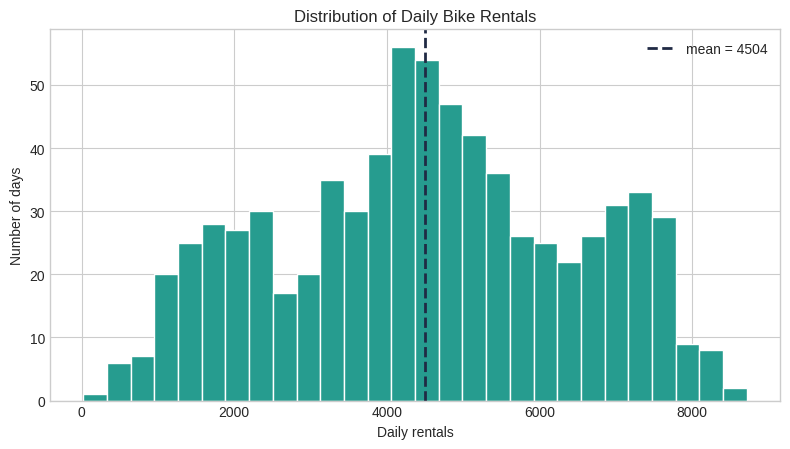

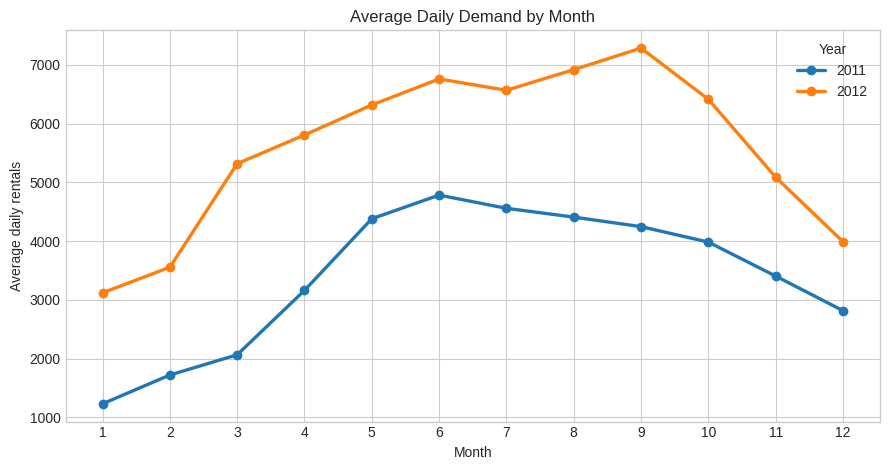

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(day["cnt"], bins=28, color="#269c8f", edgecolor="white")
ax.axvline(day["cnt"].mean(), color="#202a44", linestyle="--", linewidth=2, label=f"mean = {day['cnt'].mean():.0f}")
ax.set_title("Distribution of Daily Bike Rentals")
ax.set_xlabel("Daily rentals")
ax.set_ylabel("Number of days")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "target_distribution.pdf")
fig.savefig(FIG_DIR / "target_distribution.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.8))
monthly = day.groupby(["yr", "mnth"], as_index=False)["cnt"].mean()
monthly["year"] = monthly["yr"].map({0: "2011", 1: "2012"})
for year, group in monthly.groupby("year"):
    ax.plot(group["mnth"], group["cnt"], marker="o", linewidth=2.4, label=year)
ax.set_title("Average Daily Demand by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Average daily rentals")
ax.set_xticks(range(1, 13))
ax.legend(title="Year")
fig.tight_layout()
fig.savefig(FIG_DIR / "monthly_trend.pdf")
fig.savefig(FIG_DIR / "monthly_trend.png", dpi=180)
plt.show()

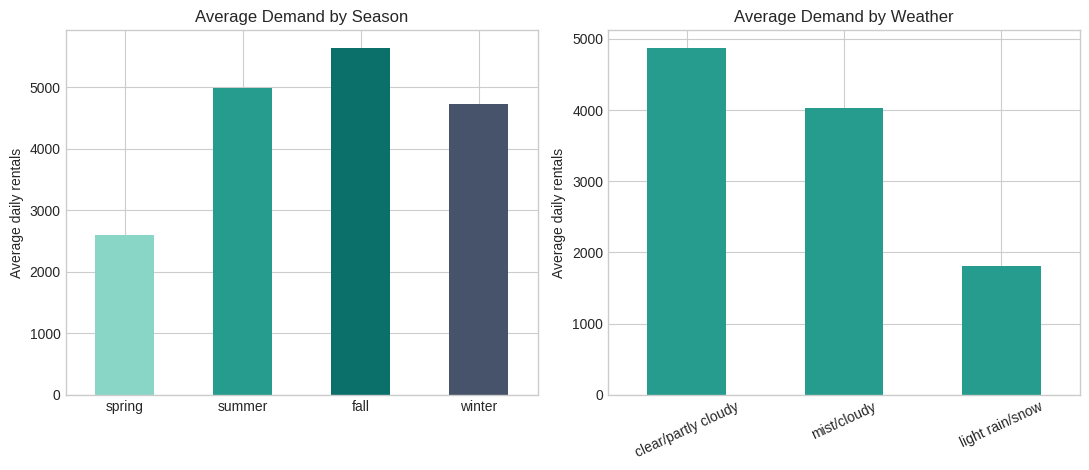

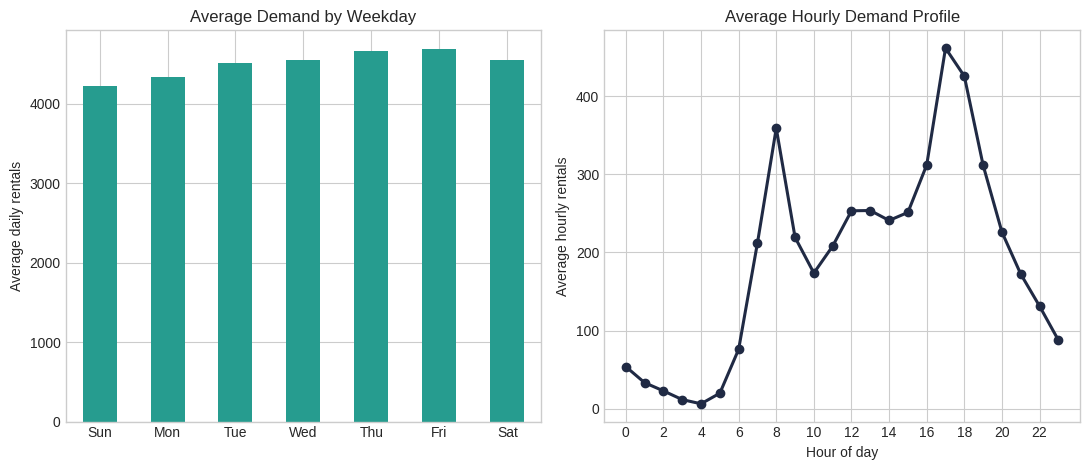

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

season_order = ["spring", "summer", "fall", "winter"]
day.groupby("season_label")["cnt"].mean().reindex(season_order).plot(
    kind="bar", ax=axes[0], color=["#89d6c7", "#269c8f", "#0b6f6a", "#46536a"]
)
axes[0].set_title("Average Demand by Season")
axes[0].set_xlabel("")
axes[0].set_ylabel("Average daily rentals")
axes[0].tick_params(axis="x", rotation=0)

weather_order = ["clear/partly cloudy", "mist/cloudy", "light rain/snow", "heavy rain/snow"]
weather_mean = day.groupby("weather_label")["cnt"].mean().reindex(weather_order).dropna()
weather_mean.plot(kind="bar", ax=axes[1], color="#269c8f")
axes[1].set_title("Average Demand by Weather")
axes[1].set_xlabel("")
axes[1].set_ylabel("Average daily rentals")
axes[1].tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(FIG_DIR / "season_weather.pdf")
fig.savefig(FIG_DIR / "season_weather.png", dpi=180)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
weekday_order = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
day.groupby("weekday_label")["cnt"].mean().reindex(weekday_order).plot(
    kind="bar", ax=axes[0], color="#269c8f"
)
axes[0].set_title("Average Demand by Weekday")
axes[0].set_xlabel("")
axes[0].set_ylabel("Average daily rentals")
axes[0].tick_params(axis="x", rotation=0)

hourly_profile = hour.groupby("hr")["cnt"].mean()
axes[1].plot(hourly_profile.index, hourly_profile.values, marker="o", color="#202a44", linewidth=2.2)
axes[1].set_title("Average Hourly Demand Profile")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Average hourly rentals")
axes[1].set_xticks(range(0, 24, 2))

fig.tight_layout()
fig.savefig(FIG_DIR / "weekday_hourly.pdf")
fig.savefig(FIG_DIR / "weekday_hourly.png", dpi=180)
plt.show()

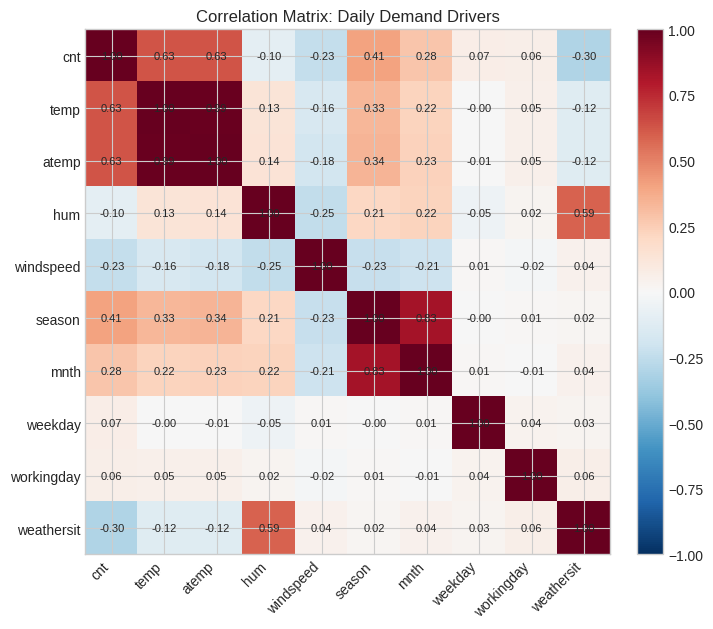

cnt           1.000
atemp         0.631
temp          0.627
season        0.406
mnth          0.280
weekday       0.067
workingday    0.061
hum          -0.101
windspeed    -0.235
weathersit   -0.297
Name: cnt, dtype: float64

In [7]:
corr_cols = ["cnt", "temp", "atemp", "hum", "windspeed", "season", "mnth", "weekday", "workingday", "weathersit"]
corr = day[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(7.6, 6.4))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation Matrix: Daily Demand Drivers")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "correlation_matrix.pdf")
fig.savefig(FIG_DIR / "correlation_matrix.png", dpi=180)
plt.show()

corr["cnt"].sort_values(ascending=False).round(3)

## 5. Main Analysis: Supervised Demand Prediction

The target is `cnt`, the total daily rentals. An 80/20 chronological split trains on earlier observations and evaluates on later observations, avoiding random temporal mixing.

Models include a mean baseline, linear regression, polynomial regression, ridge, lasso, and a depth-limited decision tree. Hyperparameters are fixed for a transparent benchmark; no validation-set tuning is performed.

The weather variables here are historical observations. Operational forecasting would require weather forecasts available at prediction time.


In [8]:
target = "cnt"
leakage_cols = ["instant", "dteday", "casual", "registered", "cnt", "season_label", "weather_label", "weekday_label"]
feature_cols = [c for c in day.columns if c not in leakage_cols]

cutoff = int(len(day) * 0.80)
train = day.iloc[:cutoff].copy()
test = day.iloc[cutoff:].copy()

X_train, y_train = train[feature_cols], train[target]
X_test, y_test = test[feature_cols], test[target]

categorical_features = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]
numeric_features = ["temp", "atemp", "hum", "windspeed"]

preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
    ]
)

poly_preprocess = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                ]
            ),
            numeric_features,
        ),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
    ]
)

models = {
    "Mean baseline": None,
    "Linear regression": (preprocess, LinearRegression()),
    "Polynomial regression": (poly_preprocess, LinearRegression()),
    "Ridge regression": (preprocess, Ridge(alpha=10.0)),
    "Lasso regression": (preprocess, Lasso(alpha=10.0, max_iter=20000)),
    "Decision tree": (preprocess, DecisionTreeRegressor(max_depth=5, min_samples_leaf=12, random_state=RANDOM_STATE)),
}

rows = []
fitted_models = {}
predictions = {}

for name, model_spec in models.items():
    if model_spec is None:
        pred = np.full_like(y_test, fill_value=y_train.mean(), dtype=float)
        fitted_models[name] = None
    else:
        model_preprocess, model = model_spec
        pipe = Pipeline([("preprocess", model_preprocess), ("model", model)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        fitted_models[name] = pipe
    predictions[name] = pred
    rows.append(
        {
            "model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred),
            "MAPE": np.mean(np.abs((y_test - pred) / y_test)) * 100,
        }
    )

metrics = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
best_model_name = metrics.iloc[0]["model"]
best_pred = predictions[best_model_name]

metrics.round(3)

,model,MAE,RMSE,R2,MAPE
0,Linear regression,803.625,1102.662,0.654,139.978
1,Ridge regression,884.251,1141.618,0.629,144.283
2,Lasso regression,900.169,1176.357,0.606,142.557
3,Decision tree,1083.329,1307.953,0.513,184.711
4,Mean baseline,2290.413,2560.556,-0.866,176.572
5,Polynomial regression,1000.146,3165.228,-1.851,126.773


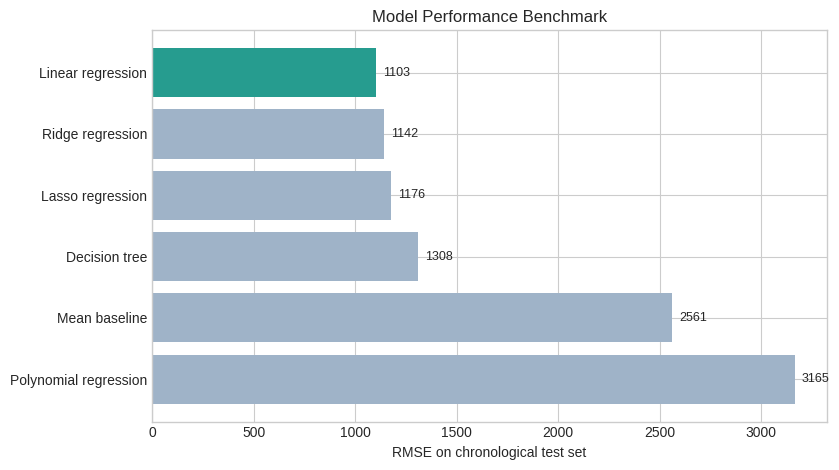

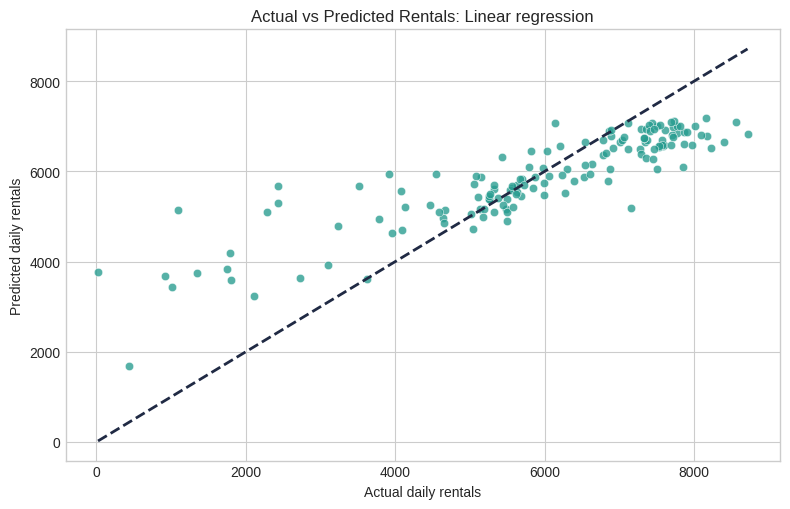

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
plot_metrics = metrics.sort_values("RMSE", ascending=True)
colors = ["#269c8f" if m == best_model_name else "#9fb3c8" for m in plot_metrics["model"]]
ax.barh(plot_metrics["model"], plot_metrics["RMSE"], color=colors)
ax.set_title("Model Performance Benchmark")
ax.set_xlabel("RMSE on chronological test set")
ax.invert_yaxis()
for i, value in enumerate(plot_metrics["RMSE"]):
    ax.text(value + 35, i, f"{value:.0f}", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "model_performance.pdf")
fig.savefig(FIG_DIR / "model_performance.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.scatter(y_test, best_pred, color="#269c8f", alpha=0.78, edgecolor="white", linewidth=0.4)
line_min = min(y_test.min(), best_pred.min())
line_max = max(y_test.max(), best_pred.max())
ax.plot([line_min, line_max], [line_min, line_max], color="#202a44", linestyle="--", linewidth=2)
ax.set_title(f"Actual vs Predicted Rentals: {best_model_name}")
ax.set_xlabel("Actual daily rentals")
ax.set_ylabel("Predicted daily rentals")
fig.tight_layout()
fig.savefig(FIG_DIR / "actual_vs_predicted.pdf")
fig.savefig(FIG_DIR / "actual_vs_predicted.png", dpi=180)
plt.show()

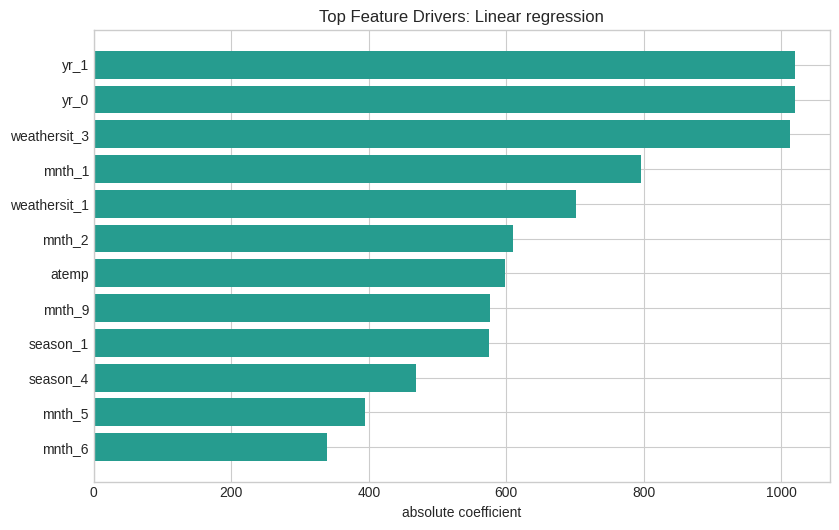

,feature,driver_score
9,yr_1,1019.9841
8,yr_0,1019.9841
35,weathersit_3,1013.1761
10,mnth_1,796.4853
33,weathersit_1,701.2250
11,mnth_2,609.5731
1,atemp,597.7076
18,mnth_9,576.4144
4,season_1,575.2873
7,season_4,469.0710


In [10]:
best_pipe = fitted_models[best_model_name]
feature_importance_table = pd.DataFrame()
driver_score_label = "driver score"
if best_pipe is not None:
    feature_names = best_pipe.named_steps["preprocess"].get_feature_names_out()
    model = best_pipe.named_steps["model"]
    if hasattr(model, "feature_importances_"):
        scores = model.feature_importances_
        driver_score_label = "model importance"
    elif hasattr(model, "coef_"):
        scores = np.abs(np.ravel(model.coef_))
        driver_score_label = "absolute coefficient"
    else:
        scores = None

    if scores is not None:
        feature_importance_table = (
            pd.DataFrame({"feature": feature_names, "driver_score": scores})
            .sort_values("driver_score", ascending=False)
            .head(12)
        )
    feature_importance_table["feature"] = (
        feature_importance_table["feature"]
        .str.replace("num__", "", regex=False)
        .str.replace("cat__", "", regex=False)
    )

    fig, ax = plt.subplots(figsize=(8.5, 5.4))
    ordered = feature_importance_table.iloc[::-1]
    ax.barh(ordered["feature"], ordered["driver_score"], color="#269c8f")
    ax.set_title(f"Top Feature Drivers: {best_model_name}")
    ax.set_xlabel(driver_score_label)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "feature_importance.pdf")
    fig.savefig(FIG_DIR / "feature_importance.png", dpi=180)
    plt.show()

feature_importance_table.round(4)

## 6. Results Summary and Conclusions

Model results are ranked by test-set RMSE; MAE and R² provide additional context. MAPE can be unstable because actual rentals are very low on some days (minimum: 22). Feature coefficient magnitudes describe the fitted model, not causal effects.


In [11]:
top_corr = corr["cnt"].drop("cnt").sort_values(key=lambda s: s.abs(), ascending=False)
test_start = str(test["dteday"].min().date())
test_end = str(test["dteday"].max().date())

results = {
    "dataset": {
        "daily_rows": int(len(day)),
        "hourly_rows": int(len(hour)),
        "date_min": str(day["dteday"].min().date()),
        "date_max": str(day["dteday"].max().date()),
        "mean_daily_cnt": float(day["cnt"].mean()),
        "median_daily_cnt": float(day["cnt"].median()),
        "max_daily_cnt": int(day["cnt"].max()),
        "missing_values": int(day.isna().sum().sum() + hour.isna().sum().sum()),
    },
    "eda": {
        "corr_temp_cnt": float(corr.loc["temp", "cnt"]),
        "corr_hum_cnt": float(corr.loc["hum", "cnt"]),
        "corr_windspeed_cnt": float(corr.loc["windspeed", "cnt"]),
        "best_month": int(day.groupby("mnth")["cnt"].mean().idxmax()),
        "best_season": str(day.groupby("season_label")["cnt"].mean().idxmax()),
        "peak_hour": int(hour.groupby("hr")["cnt"].mean().idxmax()),
        "top_correlations": {k: float(v) for k, v in top_corr.head(5).items()},
    },
    "modeling": {
        "target": target,
        "train_rows": int(len(train)),
        "test_rows": int(len(test)),
        "test_start": test_start,
        "test_end": test_end,
        "feature_cols": feature_cols,
        "best_model": str(best_model_name),
        "metrics": metrics.to_dict(orient="records"),
        "top_features": feature_importance_table.to_dict(orient="records"),
    },
}

with open(FIG_DIR / "analysis_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print(f"Best model: {best_model_name}")
print(metrics.round(2).to_string(index=False))

Best model: Linear regression
                model     MAE    RMSE    R2   MAPE
    Linear regression  803.63 1102.66  0.65 139.98
     Ridge regression  884.25 1141.62  0.63 144.28
     Lasso regression  900.17 1176.36  0.61 142.56
        Decision tree 1083.33 1307.95  0.51 184.71
        Mean baseline 2290.41 2560.56 -0.87 176.57
Polynomial regression 1000.15 3165.23 -1.85 126.77
